In [1]:
pip install datasets

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments

import torch
from torch.utils.data import DataLoader
from datasets import Dataset

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

/opt/anaconda3/envs/myenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data = pd.read_csv("/Users/mriduln/Documents/Coding/DataSci/Combined Data.csv")
data.dropna(inplace=True)
data.drop(columns=['Unnamed: 0'], axis=1, inplace=True)
data

,statement,status
0,oh my gosh,Anxiety
1,"trouble sleeping, confused mind, restless hear...",Anxiety
2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety
3,I've shifted my focus to something else but I'...,Anxiety
4,"I'm restless and restless, it's been a month n...",Anxiety
...,...,...
53038,Nobody takes me seriously I’ve (24M) dealt wit...,Anxiety
53039,"selfishness ""I don't feel very good, it's lik...",Anxiety
53040,Is there any way to sleep better? I can't slee...,Anxiety
53041,"Public speaking tips? Hi, all. I have to give ...",Anxiety


In [3]:
data = data.sample(n=6000, random_state=42).reset_index(drop=True)
data

,statement,status
0,I'm lazy to complain about it ba ihh,Normal
1,i think the wifi on my iphone is broken it wil...,Normal
2,Good tracking apps? I've been trying to find a...,Bipolar
3,I have recently looked into reddit and found t...,Depression
4,that's your favorite thing to do?,Normal
...,...,...
5995,What is around you right now? A photo? A comfo...,Depression
5996,I am tired. I am ready for everything to be ov...,Suicidal
5997,? What if I am at a friends party and a man wh...,Stress
5998,if it add any kind of info m almost the thing ...,Depression


Data Preprocessing

In [4]:
import re
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

stop_words = set(stopwords.words("english"))

def clean_statement(text):
    #lower casing
    text = text.lower()

    #remove everything except letters
    text = re.sub(r"[^a-zA-Z\s]",'',text)

    #tokenzation (splitting)
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

# clean_statement("This is lovely video to #@#@#@#@$@## 983459 watch lovely on this AI with Noor Channel")
data['statement'] = data['statement'].apply(clean_statement)


[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/mriduln/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [5]:
data['status'].value_counts()

status
Normal                  1894
Depression              1730
Suicidal                1219
Anxiety                  429
Stress                   304
Bipolar                  293
Personality disorder     131
Name: count, dtype: int64

3. Encoding

In [6]:
#label encoding for status column
label_encoder = LabelEncoder()
data['label'] = label_encoder.fit_transform(data['status'])
data

,statement,status,label
0,im lazy complain ba ihh,Normal,3
1,think wifi iphone broken quot connect quot act...,Normal,3
2,good tracking apps ive trying find apps track ...,Bipolar,1
3,recently looked reddit found place actually qu...,Depression,2
4,thats favorite thing,Normal,3
...,...,...,...
5995,around right photo comfortable place sit beaut...,Depression,2
5996,tired ready everything life pointless painful ...,Suicidal,6
5997,friends party man whispers ear likes stare tou...,Stress,5
5998,add kind info almost thing ive always felt kin...,Depression,2


Train Test Split

In [ ]:
train_texts, test_texts, train_labels, test_labels = train_test_split(data['statement'], data['label'], test_size=0.2, random_state=42, stratify=data['label'])

2 balance dataset

In [ ]:
from imblearn.over_sampling import RandomOverSampler

# Only balance the TRAINING data — test stays untouched and realistic
train_df = pd.DataFrame({'statement': train_texts, 'label': train_labels})

ros = RandomOverSampler(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = ros.fit_resample(train_df[['statement']], train_df['label'])

train_texts = X_resampled['statement'].reset_index(drop=True)
train_labels = y_resampled.reset_index(drop=True)

print(train_labels.value_counts())

label
3    1515
2    1515
1    1515
0    1515
6    1515
5    1515
4    1515
Name: count, dtype: int64


Tokenization

In [9]:
max([len(text) for text in data['statement']])

5893

In [10]:
#Tokenization using BERT tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

train_encodings = tokenizer(list(train_texts), padding=True, truncation=True, max_length=200)
test_encodings = tokenizer(list(test_texts), padding=True, truncation=True, max_length=200)

train_encodings

In [11]:
train_dataset = Dataset.from_dict({'input_ids': train_encodings['input_ids'], 'attention_mask': train_encodings['attention_mask'], 'labels': train_labels.tolist()})

test_dataset = Dataset.from_dict({'input_ids': test_encodings['input_ids'], 'attention_mask': test_encodings['attention_mask'], 'labels': test_labels.tolist()})



In [12]:
train_dataset[0]

Fine Tune Model


In [13]:
len(label_encoder.classes_)

7

In [14]:
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=len(label_encoder.classes_))

#set training arguments with improvemens
training_args = TrainingArguments(
    output_dir="./results", #output dir for results
    evaluation_strategy="epoch", #Evaluate once per epoch
    save_strategy="epoch", #save model at the end of each epoch to match evaluation
    learning_rate = 2e-5, #Learning rate
    per_device_train_batch_size =16, #Batch size for training
    per_device_eval_batch_size=16, #Batch size for evaluation
    num_train_epochs=5, #Increase number of epochs
    weight_decay=0.01, #Strength of weight decay
    logging_dir="./logs", #Directory for logging
    logging_steps=10, #Log every 10 steps
    lr_scheduler_type="linear", #Use linear learning rate scheduler with warmup
    warmup_steps=500, #Number of warmup steps for learning rate scheduler
    load_best_model_at_end=True, #Load the best model at the end of training
)
trainer =Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset = test_dataset,
)

trainer.train()

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/opt/anaconda3/envs/myenv/lib/python3.10/site-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss
1,0.505400,0.706044
2,0.245800,0.691200
3,0.140300,0.845494
4,0.010700,0.983881
5,0.072400,1.101432


/opt/anaconda3/envs/myenv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/envs/myenv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/envs/myenv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
/opt/anaconda3/envs/myenv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)


TrainOutput(global_step=3315, training_loss=0.36766318441010437, metrics={'train_runtime': 2242.079, 'train_samples_per_second': 23.65, 'train_steps_per_second': 1.479, 'total_flos': 5450035169250000.0, 'train_loss': 0.36766318441010437, 'epoch': 5.0})

In [13]:
#Cell That Loads the saved model
from transformers import AutoModelForSequenceClassification, AutoTokenizer
import pickle

SAVE_DIR = "/Users/mriduln/Documents/Coding/DataSci/saved_mental_status_bert"

model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR)
tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
label_encoder = pickle.load(open(f"{SAVE_DIR}/label_encoder.pkl", "rb"))

trainer = Trainer(model=model)  # Trainer's already imported in cell 1

Evaluate

/opt/anaconda3/envs/myenv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)


                      precision    recall  f1-score   support

             Anxiety       0.83      0.85      0.84        86
             Bipolar       0.64      0.83      0.72        58
          Depression       0.76      0.60      0.67       346
              Normal       0.93      0.88      0.91       379
Personality disorder       0.62      0.62      0.62        26
              Stress       0.53      0.70      0.61        61
            Suicidal       0.61      0.75      0.68       244

            accuracy                           0.75      1200
           macro avg       0.70      0.75      0.72      1200
        weighted avg       0.77      0.75      0.76      1200



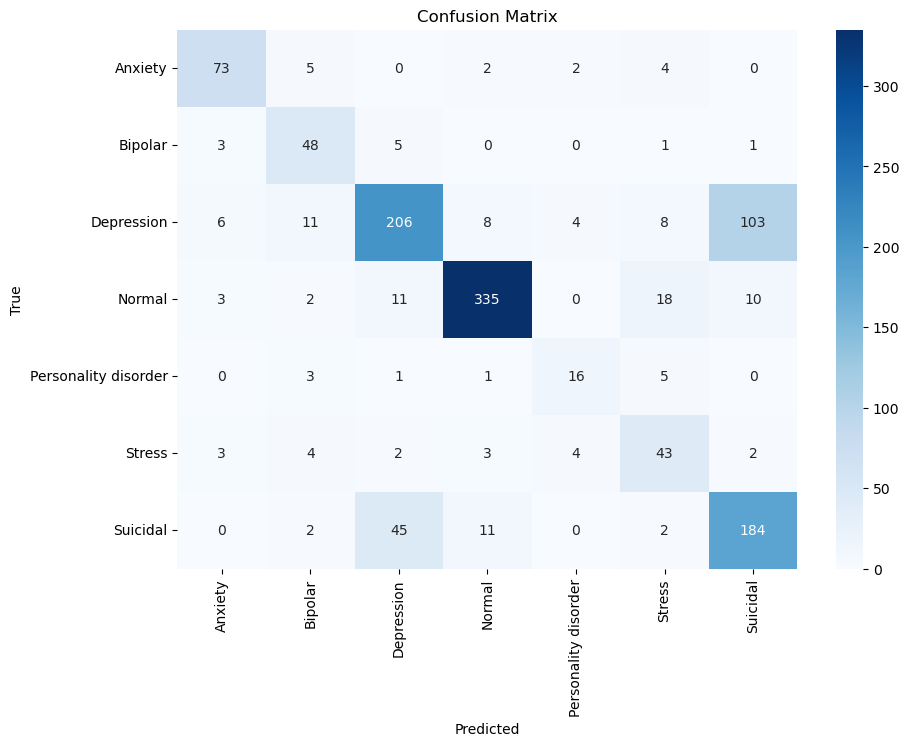

In [15]:
#predictions
predictions, labels, _ = trainer.predict(test_dataset)

#convert predictions to class labels
predicted_labels = np.argmax(predictions, axis=1)

#Classification Report
print(classification_report(test_labels, predicted_labels, target_names = label_encoder.classes_))

#Confusion matrix
cm = confusion_matrix(test_labels, predicted_labels)
plt.figure(figsize=(10,7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels= label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

Save Model and Load Model


In [16]:
trainer.save_model("/Users/mriduln/Documents/Coding/DataSci/saved_mental_status_bert") #saved model to sepcidied directory
tokenizer.save_pretrained("/Users/mriduln/Documents/Coding/DataSci/saved_mental_status_bert") #save the tokenizer

import pickle


In [17]:
pickle.dump(label_encoder, open("/Users/mriduln/Documents/Coding/DataSci/saved_mental_status_bert/label_encoder.pkl", "wb"))

In [22]:
import os
print(os.listdir("/Users/mriduln/Documents/Coding/DataSci/saved_mental_status_bert"))

['model.safetensors', 'label_encoder.pkl', 'tokenizer_config.json', 'special_tokens_map.json', 'config.json', 'training_args.bin', 'vocab.txt']


Detection System

In [18]:
import torch

def detect_anxiety(text):
    text = clean_statement(text)
    inputs = tokenizer(text, return_tensors='pt', padding=True, truncation=True, max_length=200).to(model.device)
    outputs = model(**inputs)
    logits = outputs.logits
    predicted_label = torch.argmax(logits, dim=1).item()

    return label_encoder.inverse_transform([predicted_label])[0]

# Test detection system with a mixture of normal, anxiety, bipolar, depression, suicidal
sample_texts = [
    "I feel perfectly fine today, nothing to worry about.",
    "I can't stop thinking about what will happen if things go wrong.",
    "Lately, I've been on a high, feeling like I can do anything!",
    "I'm so sad, I just can't seem to get out of bed anymore.",
    "I'm constantly thinking about how much better everyone else is doing than me.",
    "I don't think I can keep going, everything feels so hopeless.",
    "I had a really good day, spent some time with my friends.",
    "I'm overwhelmed by the idea that I might lose everything.",
    "I feel like nothing matters anymore, I just want to give up.",
    "I'm okay today, but sometimes I get really anxious for no reason."
]

#Assuming the detect_anxoety function is already defined and takes a sentence as input
for text in sample_texts:
    predicted_class = detect_anxiety(text)
    print(f"Sentence: {text}\nPredicted Class: {predicted_class}\n")


Sentence: I feel perfectly fine today, nothing to worry about.
Predicted Class: Anxiety

Sentence: I can't stop thinking about what will happen if things go wrong.
Predicted Class: Suicidal

Sentence: Lately, I've been on a high, feeling like I can do anything!
Predicted Class: Anxiety

Sentence: I'm so sad, I just can't seem to get out of bed anymore.
Predicted Class: Normal

Sentence: I'm constantly thinking about how much better everyone else is doing than me.
Predicted Class: Normal

Sentence: I don't think I can keep going, everything feels so hopeless.
Predicted Class: Depression

Sentence: I had a really good day, spent some time with my friends.
Predicted Class: Normal

Sentence: I'm overwhelmed by the idea that I might lose everything.
Predicted Class: Suicidal

Sentence: I feel like nothing matters anymore, I just want to give up.
Predicted Class: Depression

Sentence: I'm okay today, but sometimes I get really anxious for no reason.
Predicted Class: Anxiety

